# B02-KM — K-Means trên RFM (log1p F, M giữ nguyên Recency + Standard + PCA 90%)

Thí nghiệm **B02-KM** (người chạy: Nguyên) theo chiến lược model. So với B01, **chỉ khác ở Recency**: B01 áp `log1p` cho cả R, F, M; B02 chỉ áp `log1p` cho F, M và **giữ Recency ở thang gốc**. Pipeline: làm sạch → RFM → `log1p` (F, M) → StandardScaler → PCA giữ ≥ 90% phương sai → K-Means. Mục đích: đo tác động của `log1p` lên Recency.

Dữ liệu, seed, lưới k và quy tắc chọn k (Silhouette lớn nhất) giữ nguyên như A01-KM / A02-KM / A03-KM. B01-KM chưa có trong repo nên được dựng lại ngay trong notebook để so cùng điều kiện.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
LOG_FEATURES = ["Frequency", "Monetary"]   # B02: log1p chỉ F, M; Recency giữ nguyên
PCA_VAR = 0.90                # giữ ít nhất 90% phương sai (giống A01, B01)
K_GRID = range(2, 11)         # quét k = 2..10 (giống A02-KM, A03-KM)
RANDOM_STATE = 42
N_INIT = 20

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-KM, A02-KM, A03-KM), không sao chép thêm
REL = "notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv"
DATA = next(c for p in [Path.cwd(), *Path.cwd().parents]
            for c in (p / REL, p / "project" / REL) if c.exists())
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4.327 khách, 3 biến RFM, không thiếu giá trị, không có giá trị âm (điều kiện để dùng `log1p`). Đây là file làm sạch cũ của nhóm, không phải RFM tính thẳng từ raw (chi tiết ở A02-KM); các thí nghiệm cùng dùng file này nên so sánh được với nhau.

## Biến đổi: `log1p` cho F, M; giữ Recency

Thay đổi duy nhất so với B01 là Recency không qua `log1p`.

In [3]:
def make_pre():
    # Thứ tự cột ra vẫn là Recency, Frequency, Monetary
    return ColumnTransformer([("recency", "passthrough", ["Recency"]),
                              ("log_fm", FunctionTransformer(np.log1p), LOG_FEATURES)])

X_t = make_pre().fit_transform(X)
manual = X.copy(); manual[LOG_FEATURES] = np.log1p(manual[LOG_FEATURES])
assert np.allclose(X_t, manual.to_numpy())

skew = pd.DataFrame({"skew_raw": X.skew(),
                     "skew_B02 (R gốc, F/M log1p)": pd.DataFrame(X_t, columns=FEATURES).skew(),
                     "skew_B01 (cả ba log1p)": np.log1p(X).skew()}).round(2)
skew

,skew_raw,"skew_B02 (R gốc, F/M log1p)",skew_B01 (cả ba log1p)
Recency,1.25,1.25,-0.33
Frequency,11.95,1.21,1.21
Monetary,21.04,0.35,0.35


**Nhận xét:** Recency vốn lệch phải vừa phải (1,25), nhẹ hơn nhiều so với Frequency (11,95) và Monetary (21,04), nên chỉ F và M thật sự cần `log1p`. B02 đưa F về 1,21 và M về 0,35 nhưng giữ Recency 1,25; B01 còn kéo Recency sang lệch trái (−0,33). Câu hỏi của thí nghiệm là việc nén thêm Recency này có làm đổi cách chia cụm hay không.

## Chuẩn hóa và PCA giữ 90% phương sai

In [4]:
X_scaled = StandardScaler().fit_transform(X_t)

cum = np.cumsum(PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)

print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")
pd.DataFrame(pca.components_, index=[f"PC{i+1}" for i in range(n_pc)], columns=FEATURES).round(3)

Phương sai tích lũy: [0.723  0.9381 1.    ]
Số PC giữ lại: 2 / 3 (phương sai giữ 93.81%)


,Recency,Frequency,Monetary
PC1,-0.483,0.623,0.615
PC2,0.875,0.310,0.373


**Nhận xét:** PC1 giữ 72,30% và PC2 giữ thêm 21,51%, cộng lại 93,81% nên **chỉ cần 2 PC để đạt 90%**. Khác A01/A02 (RFM thô phải giữ đủ 3/3 PC nên PCA chỉ xoay trục), PCA ở B02 thực sự giảm chiều từ 3 xuống 2, giống B01 (94,01%).

## Quét số cụm k

Chọn k theo **Silhouette lớn nhất** — cùng quy tắc các thí nghiệm K-Means khác. Mọi chỉ số tính trên `Z` (không gian mô hình được fit). Cột `min_cluster` là số khách của cụm nhỏ nhất.

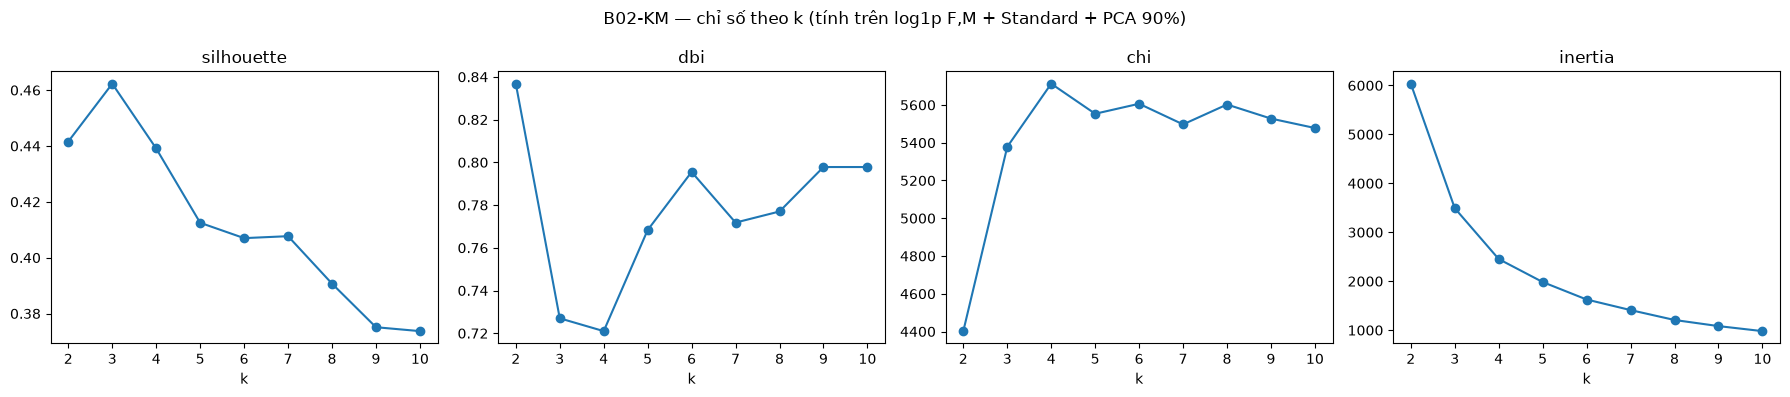

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.4416,0.8368,4402.1,6034.7,1826
1,3,0.4623,0.7270,5378.2,3491.5,970
2,4,0.4391,0.7210,5712.6,2452.9,530
3,5,0.4125,0.7683,5553.4,1983.3,303
4,6,0.4070,0.7955,5606.4,1626.3,266
5,7,0.4077,0.7718,5497.1,1410.2,268
6,8,0.3907,0.7770,5602.4,1208.0,132
7,9,0.3751,0.7978,5527.9,1083.2,66
8,10,0.3737,0.7978,5477.9,980.4,66


In [5]:
def sweep(Zs):
    rows, labels_by_k = [], {}
    for k in K_GRID:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Zs)
        labels_by_k[k] = km.labels_
        rows.append({"k": k,
                     "silhouette": round(silhouette_score(Zs, km.labels_), 4),
                     "dbi": round(davies_bouldin_score(Zs, km.labels_), 4),
                     "chi": round(calinski_harabasz_score(Zs, km.labels_), 1),
                     "inertia": round(km.inertia_, 1),
                     "min_cluster": int(np.bincount(km.labels_).min())})
    return pd.DataFrame(rows), labels_by_k

metrics, labels_by_k = sweep(Z)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "chi", "inertia"]):
    ax.plot(metrics["k"], metrics[col], marker="o")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("B02-KM — chỉ số theo k (tính trên log1p F,M + Standard + PCA 90%)")
plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics.png", dpi=150)
plt.show()
metrics

**Nhận xét:** Silhouette cao nhất ở **k = 3** (0,4623), gần k = 2 (0,4416) và k = 4 (0,4391), rồi giảm dần đến 0,37 ở k = 10. DBI thấp nhất ở k = 4 (0,7210) nhưng sát k = 3 (0,7270); CHI tăng đến k = 4 rồi đi ngang quanh 5.500. Khác A02-KM (RFM thô, có cụm 2–3 khách từ k = 5), ở B02 cụm nhỏ nhất vẫn có 266 khách đến k = 7 và 66 khách ở k = 9–10: không còn hiện tượng vỡ ra từng điểm ngoại lai.

## Chọn k và huấn luyện mô hình cuối

In [6]:
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("k được chọn (Silhouette lớn nhất):", best_k)

model = Pipeline([("pre", make_pre()), ("scaler", StandardScaler()),
                  ("pca", PCA(n_components=n_pc, svd_solver="full")),
                  ("kmeans", KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT))]).fit(X)
labels = model["kmeans"].labels_
assert (labels == labels_by_k[best_k]).all()      # pipeline cho đúng nhãn đã quét ở trên
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))

k được chọn (Silhouette lớn nhất): 3
0    2020
1    1337
2     970
Name: Số khách, dtype: int64


**Nhận xét:** k = 3 chia 2.020 / 1.337 / 970 khách (46,7% / 30,9% / 22,4%) — ba cụm cỡ tương đương nhau, không còn tình trạng một cụm chiếm gần hết như A02-KM (4.303 / 24).

## Hồ sơ cụm

Mô tả bằng trung vị RFM **trên thang gốc** (không phải log). `Monetary_share_pct` là tỷ trọng tổng Monetary của cụm.

In [7]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum")
prof.round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,2020,47.0,2.0,496.1,46.7,14.2
1,1337,18.0,7.0,2468.0,30.9,81.3
2,970,253.0,1.0,286.5,22.4,4.6


**Nhận xét** (tên nhóm chỉ là cách gọi gợi ý từ trung vị RFM):
- Cụm 1 (1.337 khách, 30,9%): Recency 18, Frequency 7, Monetary ≈ 2.468 → **mua gần đây, thường xuyên, chi nhiều**; chiếm 81,3% tổng Monetary.
- Cụm 0 (2.020 khách, 46,7%): Recency 47, Frequency 2, Monetary ≈ 496 → **mua ít, chi thấp, còn khá gần đây**; 14,2% Monetary.
- Cụm 2 (970 khách, 22,4%): Recency 253, Frequency 1, Monetary ≈ 287 → **mua một lần, lâu chưa quay lại**; 4,6% Monetary.

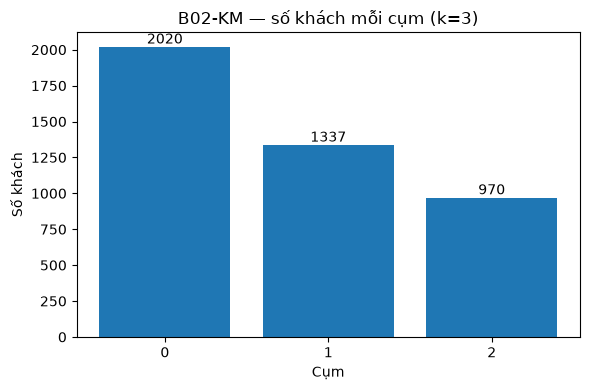

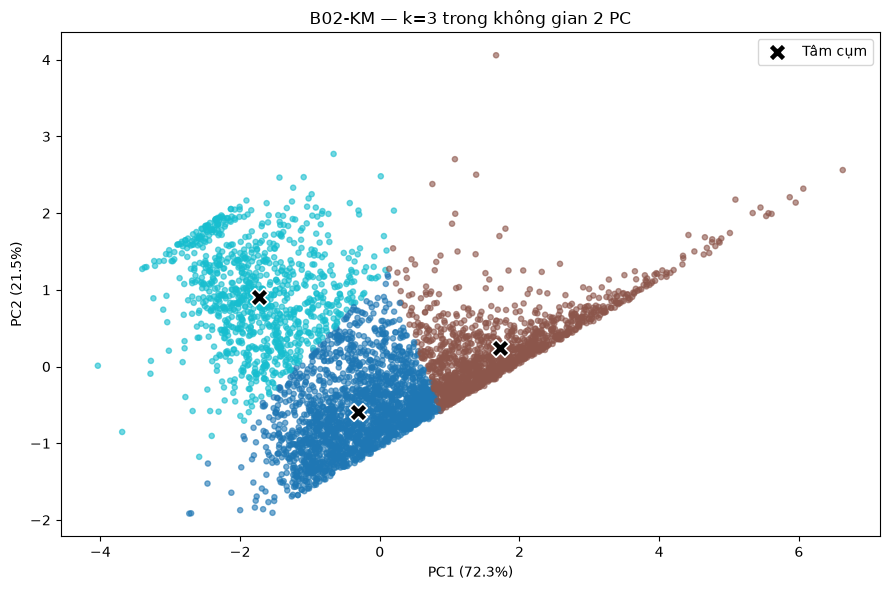

In [8]:
# Hình 1: số khách mỗi cụm
sizes = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(sizes.index.astype(str), sizes.values); ax.bar_label(bars)
ax.set_xlabel("Cụm"); ax.set_ylabel("Số khách"); ax.set_title(f"B02-KM — số khách mỗi cụm (k={best_k})")
plt.tight_layout(); plt.savefig(FIG / "kmeans_cluster_distribution.png", dpi=150); plt.show()

# Hình 2: các cụm trong không gian 2 PC (đúng không gian mô hình được fit)
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=14, alpha=0.6)
ax.scatter(model["kmeans"].cluster_centers_[:, 0], model["kmeans"].cluster_centers_[:, 1], c="black", marker="X",
           s=160, edgecolors="white", linewidths=1.2, label="Tâm cụm")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title(f"B02-KM — k={best_k} trong không gian {n_pc} PC"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Ba cụm là ba vùng liền kề trong mặt phẳng 2 PC, xếp dọc theo PC1 từ nhóm lâu chưa mua (bên trái) qua nhóm mua ít (giữa) đến nhóm mua nhiều (bên phải); không có khoảng trống giữa các cụm, nên đây là cách chia một dải liên tục chứ không phải ba nhóm tách bạch.

## Đối chiếu B01 (dựng lại cùng điều kiện)

Dựng lại B01-KM (`log1p` cả R, F, M → StandardScaler → PCA 90% → K-Means, cùng lưới k, seed và quy tắc chọn) để so với B02. ARI (Adjusted Rand Index) đo mức trùng nhóm giữa hai cách chia, 1,0 là giống hệt.

In [9]:
Xb01 = StandardScaler().fit_transform(np.log1p(X))
cum_b01 = np.cumsum(PCA(svd_solver="full").fit(Xb01).explained_variance_ratio_)
n_pc_b01 = int(np.searchsorted(cum_b01, PCA_VAR) + 1)
Z_b01 = PCA(n_components=n_pc_b01, svd_solver="full").fit_transform(Xb01)
metrics_b01, labels_by_k_b01 = sweep(Z_b01)
best_k_b01 = int(metrics_b01.loc[metrics_b01["silhouette"].idxmax(), "k"])
labels_b01 = labels_by_k_b01[best_k_b01]
print(f"B01 dựng lại: {n_pc_b01}/3 PC (phương sai {cum_b01[n_pc_b01-1]:.2%}) | k được chọn = {best_k_b01}")

ari_k = pd.DataFrame({"k": list(K_GRID),
                      "ARI_B02_vs_B01": [round(adjusted_rand_score(labels_by_k[k], labels_by_k_b01[k]), 4) for k in K_GRID],
                      "silhouette_B02": metrics["silhouette"].values,
                      "silhouette_B01": metrics_b01["silhouette"].values})
print("ARI giữa cách chia ở k riêng của mỗi bên:", round(adjusted_rand_score(labels, labels_b01), 4))
ari_k

B01 dựng lại: 2/3 PC (phương sai 94.01%) | k được chọn = 2
ARI giữa cách chia ở k riêng của mỗi bên: 0.419


,k,ARI_B02_vs_B01,silhouette_B02,silhouette_B01
0,2,0.7672,0.4416,0.4639
1,3,0.3063,0.4623,0.3750
2,4,0.4491,0.4391,0.3786
3,5,0.4536,0.4125,0.3662
4,6,0.4670,0.4070,0.3703
5,7,0.5120,0.4077,0.3728
6,8,0.4285,0.3907,0.3709
7,9,0.4188,0.3751,0.3659
8,10,0.4099,0.3737,0.3596


In [10]:
def row(name, cfg, n_components, m_row, lab):
    return {"Thí nghiệm": name, "Cấu hình": cfg, "Số PC": n_components, "k": int(m_row["k"]),
            "Silhouette": m_row["silhouette"], "DBI": m_row["dbi"], "CHI": m_row["chi"], "Inertia": m_row["inertia"],
            "Kích thước cụm": sorted(np.bincount(lab).tolist(), reverse=True),
            "Silhouette trên không gian B02": round(silhouette_score(Z, lab), 4),
            "Silhouette trên không gian B01": round(silhouette_score(Z_b01, lab), 4)}

cmp = pd.DataFrame([
    row("B02-KM", "log1p F,M (giữ R) + Standard + PCA 90%", n_pc, metrics.loc[metrics.k == best_k].iloc[0], labels),
    row("B01-KM (dựng lại)", "log1p R,F,M + Standard + PCA 90%", n_pc_b01,
        metrics_b01.loc[metrics_b01.k == best_k_b01].iloc[0], labels_b01),
])
prof_b01 = X.assign(cluster=labels_b01).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"),
    Frequency=("Frequency", "median"), Monetary=("Monetary", "median"), Monetary_sum=("Monetary", "sum"))
prof_b01["customer_share_pct"] = (100 * prof_b01["customers"] / len(X)).round(2)
prof_b01["Monetary_share_pct"] = (100 * prof_b01["Monetary_sum"] / prof_b01["Monetary_sum"].sum()).round(2)
prof_b01 = prof_b01.drop(columns="Monetary_sum")
print("Hồ sơ cụm của B01 dựng lại:"); print(prof_b01.round(1).to_string())
cmp

Hồ sơ cụm của B01 dựng lại:
         customers  Recency  Frequency  Monetary  customer_share_pct  Monetary_share_pct
cluster                                                                                 
0             2667     97.0        1.0     352.7                61.6                15.4
1             1660     17.0        6.0    2016.1                38.4                84.6


,Thí nghiệm,Cấu hình,Số PC,k,Silhouette,DBI,CHI,Inertia,Kích thước cụm,Silhouette trên không gian B02,Silhouette trên không gian B01
0,B02-KM,"log1p F,M (giữ R) + Standard + PCA 90%",2,3,0.4623,0.7270,5378.2,3491.5,"[2020, 1337, 970]",0.4623,0.3197
1,B01-KM (dựng lại),"log1p R,F,M + Standard + PCA 90%",2,2,0.4639,0.8203,4985.9,5668.4,"[2667, 1660]",0.4235,0.4639


**Nhận xét:**
- **Hai nhánh đều giảm chiều thật** (cùng 2 PC: B02 93,81%, B01 94,01%) nhưng cho k khác nhau theo cùng một quy tắc: B02 chọn k = 3, B01 chọn k = 2 (Silhouette k = 2 là 0,4639; k = 3 chỉ 0,3750).
- **Khác nhau thật nhưng không hoàn toàn:** ARI ở k riêng là 0,419; ở cùng k = 2 là 0,7672 (hai cách chia khá giống nhau), ở cùng k = 3 chỉ 0,3063 (khác nhiều).
- **Khác biệt chính nằm ở nhóm "lâu chưa mua":** B02 (Recency gốc) tách riêng cụm Recency 253, Frequency 1 (22,4% khách) khỏi cụm mua ít còn gần (Recency 47). B01 (Recency log) gộp hai nhóm này vào một cụm 2.667 khách (61,6%) có Recency 97, Frequency 1; cụm còn lại 1.660 khách (38,4%) giống cụm giá trị cao của B02 (Recency 17, Frequency 6, 84,6% Monetary).
- **Silhouette không phân định được B01 và B02:** hai giá trị 0,4623 và 0,4639 gần như bằng nhau nhưng tính trên hai không gian khác nhau. Trên cùng một không gian, mỗi cách chia đều tốt nhất ở không gian của chính nó (không gian B02: 0,4623 so với 0,4235; không gian B01: 0,3197 so với 0,4639).

## Lưu kết quả

In [11]:
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_b02_labels.csv", index=False)
joblib.dump(model, "kmeans_model.pkl")

m = metrics.loc[metrics.k == best_k].iloc[0]
params = {"experiment": "B02-KM", "features": FEATURES, "log1p_features": LOG_FEATURES, "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "k": best_k, "n_customers": int(len(X)),
          "silhouette": float(m["silhouette"]), "dbi": float(m["dbi"]), "chi": float(m["chi"]), "inertia": float(m["inertia"]),
          "kmeans_params": model["kmeans"].get_params()}
json.dump(params, open("kmeans_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in Path(".").iterdir() if p.is_file()), sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['Working_details_KMeans_B02.xlsx', 'kmeans_b02.ipynb', 'kmeans_model.pkl', 'kmeans_params.json'] ['kmeans_b02_labels.csv']


## Working_details

Ghi bảng tóm tắt theo đúng bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng theo k, bảng cụm), thêm bảng đối chiếu B01.

In [12]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "KMeans_B02"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None):
    ws[cell] = value
    ws[cell].font = B if bold else Font(name="Calibri")
    if fmt: ws[cell].number_format = fmt

put("A1", "THÍ NGHIỆM K-MEANS — B02 (RFM, log1p F,M giữ Recency, Standard, PCA 90%)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; chỉ số tính trên Z (không gian đã fit). Khác B01 ở cách xử lý Recency")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary"), ("Dữ liệu train", f"Z (log1p F,M → Standard → PCA, {n_pc} PC)"),
        ("K được chọn", best_k), ("random_state", RANDOM_STATE), ("init", "k-means++"), ("n_init", N_INIT)]
right = [("max_iter", 300), ("tol", 0.0001), ("Tổng khách hàng", int(len(X))), ("Số cụm", best_k),
         ("PCA", f"90% → {n_pc}/3 PC (phương sai {cum[n_pc-1]:.2%})"),
         ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)
ws["E6"].number_format = "0.0000"

for c, v in zip("ABCDEF", ["k", "Silhouette", "DBI", "CHI", "Inertia", "Nhận xét"]): put(f"{c}12", v, bold=True)
for i, r in enumerate(metrics.itertuples(), start=13):
    put(f"A{i}", int(r.k)); put(f"B{i}", r.silhouette, fmt="0.0000"); put(f"C{i}", r.dbi, fmt="0.0000")
    put(f"D{i}", r.chi, fmt="0.00"); put(f"E{i}", r.inertia, fmt="0.00")
    note = "k được chọn (Silhouette lớn nhất)" if r.k == best_k else ""
    if r.min_cluster <= 5: note = (note + "; " if note else "") + f"cụm nhỏ nhất chỉ {r.min_cluster} khách"
    put(f"F{i}", note)

r0 = 13 + len(metrics) + 2
hdr = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)",
       "Monetary (median)", "Tỷ trọng Monetary (%)"]
for c, v in zip("ABCDEFGH", hdr): put(f"{c}{r0}", v, bold=True)
med = X.median()
def mo_ta(p):
    return ("Recency xa" if p["Recency"] > med["Recency"] else "Recency gần") + ", " + \
           ("Frequency cao" if p["Frequency"] > med["Frequency"] else "Frequency thấp") + ", " + \
           ("Monetary cao" if p["Monetary"] > med["Monetary"] else "Monetary thấp")
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    put(f"A{j}", int(cl)); put(f"B{j}", mo_ta(p)); put(f"C{j}", int(p["customers"]))
    put(f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(f"E{j}", float(p["Recency"]))
    put(f"F{j}", float(p["Frequency"])); put(f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(f"H{j}", float(p["Monetary_share_pct"]), fmt="0.00")

r1 = r0 + len(prof) + 3
put(f"A{r1}", "Đối chiếu B01-KM (dựng lại; chỉ số tính trên không gian đã fit của từng thí nghiệm)", bold=True)
for c, v in zip("ABCDEFGH", ["Thí nghiệm", "Cấu hình", "k", "Silhouette", "DBI", "CHI", "Inertia", "Kích thước cụm"]):
    put(f"{c}{r1+1}", v, bold=True)
for j, r in enumerate(cmp.itertuples(index=False), start=r1 + 2):
    vals = [r[0], r[1], int(r[3]), float(r[4]), float(r[5]), float(r[6]), float(r[7]), str(r[8])]
    for c, v in zip("ABCDEFGH", vals):
        put(f"{c}{j}", v, fmt="0.0000" if c in "DE" else ("0.00" if c in "FG" else None))
k_same = [(k, float(ari_k.loc[ari_k.k == k, "ARI_B02_vs_B01"].iloc[0])) for k in (2, 3)]
put(f"A{r1+5}", f"ARI B02 vs B01: k riêng = {adjusted_rand_score(labels, labels_b01):.4f} | cùng k=2: {k_same[0][1]:.4f} | cùng k=3: {k_same[1][1]:.4f}")
put(f"A{r1+6}", "Silhouette/DBI/CHI của hai thí nghiệm tính trên hai không gian khác nhau nên không so trực tiếp.")

for col, w in zip("ABCDEFGHI", [16, 22, 17, 19, 20, 21, 25, 22, 13]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"
wb.save("Working_details_KMeans_B02.xlsx")
print("Đã lưu Working_details_KMeans_B02.xlsx")

Đã lưu Working_details_KMeans_B02.xlsx


## Kết luận B02-KM

- **Giữ Recency ở thang gốc cho kết quả khác B01** (ARI 0,419 ở k riêng; 0,307 ở cùng k = 3): B02 chọn k = 3, B01 chọn k = 2 theo cùng quy tắc Silhouette lớn nhất.
- **B02 tách thêm nhóm "mua một lần, lâu chưa quay lại"** (Recency 253, 22,4% khách) khỏi nhóm mua ít còn gần, điều B01 gộp chung. Ba cụm cân đối (22,4% / 30,9% / 46,7%) và đọc được.
- **So với A02-KM (RFM thô):** chỉ cần `log1p` cho F, M là đủ hết hiện tượng vỡ ra cụm vài khách (cụm nhỏ nhất ≥ 66 khách ở mọi k = 2–10, so với 2–3 khách của A02 từ k = 5).
- **Giới hạn:** Silhouette không phân định được B01 và B02 (0,4639 và 0,4623 trên hai không gian khác nhau; mỗi bên thắng trên không gian của chính nó), và cả hai đều là một dải liên tục chứ không phải cụm tách bạch. Chọn B01 hay B02 cần thêm tiêu chí ngoài Silhouette (độ ổn định, giá trị nghiệp vụ).
- **Bước kế tiếp:** B04-DB (log1p + MinMax) và nhánh C.